02 — Transfer learning et choix d'architecture sous contrainte (Partie 2)

Exigence du cahier des charges : **fonctionner sur un smartphone d'entrée de gamme**. On cherche donc le meilleur compromis précision / paramètres / latence.

Plan :
1. justification des backbones (MobileNetV3-Small, MobileNetV3-Large, ResNet-50, pré-entraînés ImageNet) ;
2. comparaison des **trois stratégies** sur MobileNetV3-Large : (a) backbone gelé, (b) fine-tuning partiel, (c) fine-tuning complet à LR différencié ;
3. entraînement des autres backbones avec la stratégie retenue sur la validation ;
4. mesure des paramètres, taille, **latence CPU et GPU** (≥ 100 images, warm-up, synchronisation) ;
5. **front de Pareto** précision vs latence et vs taille (avec CNN-Plain et CNN-Res du notebook 01) ;
6. **recommandation** argumentée ; 7. *bonus* : export ONNX + quantification dynamique.

Résolution 224×224 (résolution d'entraînement ImageNet).

In [ ]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = False   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

from src.datasets import (CLASSES, IMAGENET_MEAN, IMAGENET_STD, TensorImageDataset, build_transform,
                          get_split_tensors, make_loader)
from src.latency import (count_params, export_onnx, measure_latency, model_size_mb, onnx_latency, onnx_predict,
                         pareto_front, quantize_onnx_dynamic)
from src.models import CNNPlain, CNNRes, TransferModel, apply_strategy
from src.train import final_test_evaluation, fit_classifier, load_best, record_experiment
from src.utils import load_json, save_json

P2 = cfg["part2"]
SIZE = cfg["resolution"]["transfer"]
OUT = paths["results"] / "02_transfer"
OUT.mkdir(parents=True, exist_ok=True)
BS, NW = cfg["train"]["batch_size"], cfg["data"]["num_workers"]

# Normalisation ImageNet : les filtres pré-entraînés attendent des entrées normalisées ainsi
data = get_split_tensors(paths, DATA_ROOT, SIZE)
tf_train = build_transform(True, IMAGENET_MEAN, IMAGENET_STD)
tf_eval = build_transform(False, IMAGENET_MEAN, IMAGENET_STD)
ds = {s: TensorImageDataset(x, df["label"], tf_train if s == "train" else tf_eval) for s, (df, x) in data.items()}
new_train_loader = lambda: make_loader(ds["train"], BS, True, NW, cfg["seed"])
val_loader = make_loader(ds["val"], 128, False, NW)
test_loader = make_loader(ds["test"], 128, False, NW)

## 1. Choix des backbones (idée-clé de chaque architecture)

| Backbone                      | Idée-clé (cours, complément « Grandes architectures »)                                                                                                                                                                                                                                                                                   | Rôle dans l'étude                                                                       |
|:------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:----------------------------------------------------------------------------------------|
| **MobileNetV3-Small / Large** | convolutions **séparables en profondeur** (*depthwise* 3×3 par canal + *pointwise* 1×1) : coût divisé par ~8–9 par rapport à une conv 3×3 standard ; blocs **inverted residual** à goulot linéaire (MobileNetV2) ; *squeeze-and-excitation* ; activation h-swish ; architecture trouvée par recherche automatique (NAS) pour les mobiles | modèles **légers** visés pour le smartphone ; Small vs Large = deux points du compromis |
| **ResNet-50**                 | **connexions résiduelles** (apprentissage de F(x) = H(x) − x) qui permettent d'entraîner 50 couches ; blocs *bottleneck* 1×1 → 3×3 → 1×1 (les 1×1 réduisent puis restaurent les canaux)                                                                                                                                                  | modèle **lourd** de référence : la précision qu'on « sacrifie » en allant vers le léger |

Pourquoi le transfer learning ? Les premières couches d'un réseau ImageNet détectent des contours, textures et couleurs génériques, utiles aussi pour des lésions foliaires ; on réutilise ces features au lieu de les réapprendre avec ~13 000 images.

In [4]:
for name in P2["backbones"]:
    m = TransferModel(name, len(CLASSES), pretrained=False)
    print(f"{name:20s} {count_params(m) / 1e6:6.2f} M paramètres")

mobilenet_v3_small     1.53 M paramètres
mobilenet_v3_large     4.21 M paramètres
resnet50              23.53 M paramètres


## 2. Trois stratégies sur MobileNetV3-Large

| Stratégie                                            | Ce qui est entraîné                                              | LR                           | Intérêt / risque                                                                                                                                                   |
|:-----------------------------------------------------|:-----------------------------------------------------------------|:-----------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| (a) `frozen` — extraction de features                | la nouvelle tête uniquement (BatchNorm du backbone en mode eval) | 1e-3                         | rapide, peu de risque de sur-apprentissage ; limité si le domaine diffère d'ImageNet                                                                               |
| (b) `partial` — fine-tuning des dernières couches    | 3 derniers blocs + couche dense du classifieur + tête            | 1e-4 (blocs), 1e-3 (tête)    | adapte les features **haut niveau** (spécifiques) tout en gardant les features bas niveau (génériques)                                                             |
| (c) `full` — fine-tuning complet, **LR différencié** | tout le réseau                                                   | 1e-4 (backbone), 1e-3 (tête) | meilleure adaptation ; le LR plus faible du backbone évite de « détruire » les features pré-entraînées au début, quand la tête aléatoire produit de gros gradients |

Même nombre d'epochs, même graine ; **choix sur le F1 macro de validation**.

Reprise depuis l'epoch 6 (temps déjà écoulé : 4.4 min)
Reprise depuis l'epoch 6 (temps déjà écoulé : 4.4 min)
Reprise depuis l'epoch 6 (temps déjà écoulé : 4.9 min)


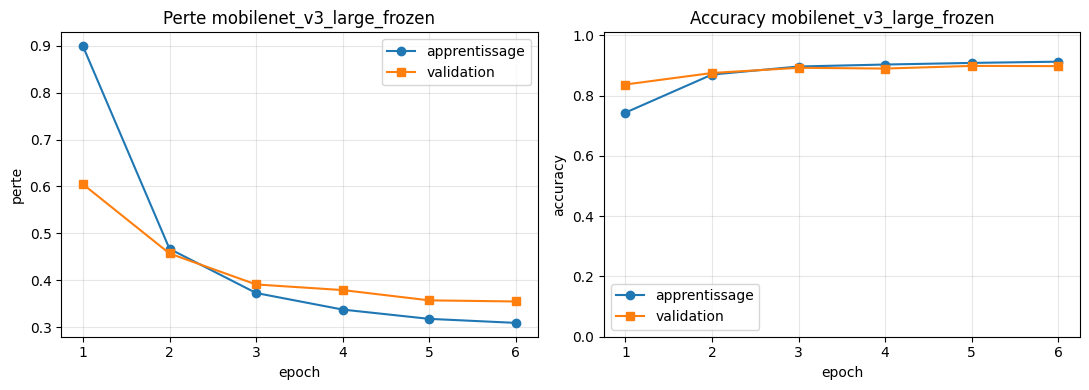

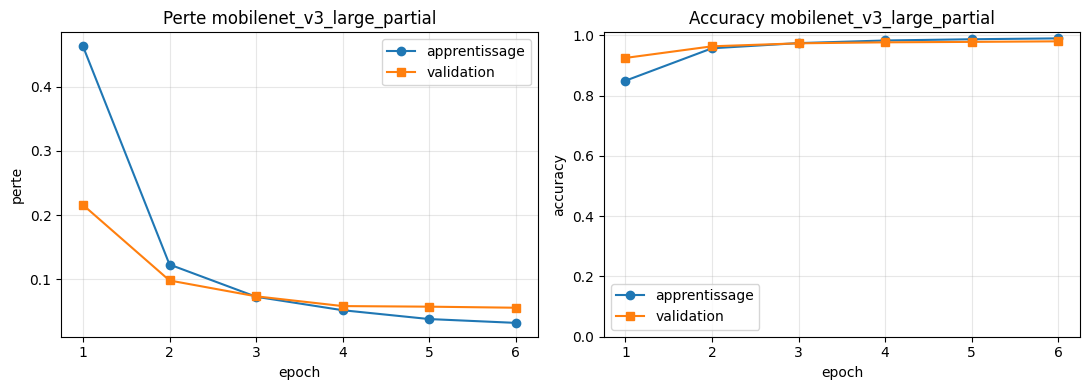

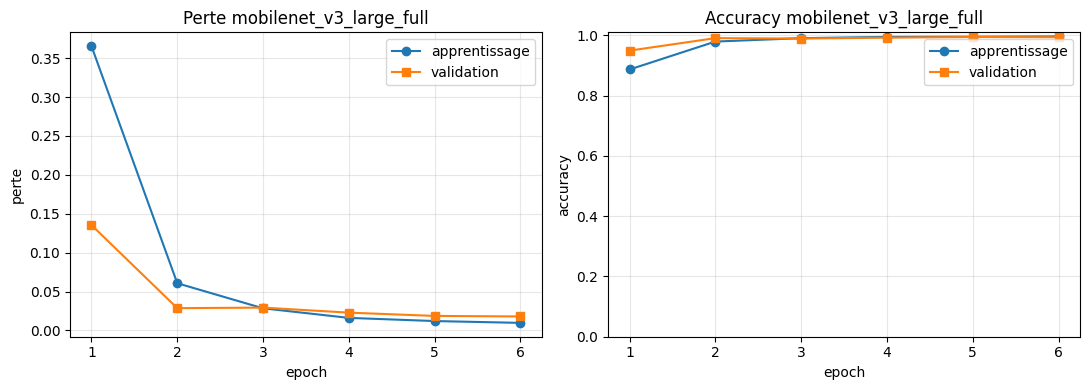

In [5]:
def run_transfer(backbone, strategy):
    set_seed(cfg["seed"])
    m = TransferModel(backbone, len(CLASSES), pretrained=P2["pretrained"])
    groups = apply_strategy(m, strategy, P2["lr_head"], P2["backbone_lr_factor"])
    hp = {"backbone": backbone, "strategy": strategy, "lr_head": P2["lr_head"],
          "backbone_lr": P2["lr_head"] * P2["backbone_lr_factor"] if strategy != "frozen" else 0,
          "epochs": P2["epochs"], "batch_size": BS, "weight_decay": P2["weight_decay"], "img_size": SIZE,
          "trainable_params": count_params(m, trainable_only=True), "optimizer": "AdamW+cosine"}
    exp = OUT / f"{backbone}_{strategy}"
    hist = fit_classifier(m, new_train_loader(), val_loader, exp, P2["epochs"], groups, P2["weight_decay"],
                          cfg["train"]["amp"], cfg["train"]["max_minutes"], cfg["train"]["resume"], hparams=hp)
    return {"model": m, "exp": exp, "hist": hist, "hp": hp, "backbone": backbone, "strategy": strategy}

runs = {}
for strat in P2["strategies"]:
    runs[(P2["strategy_study_backbone"], strat)] = run_transfer(P2["strategy_study_backbone"], strat)

F1 val max : {'frozen': 0.8703, 'partial': 0.9747, 'full': 0.9936}
Stratégie retenue (validation) : full


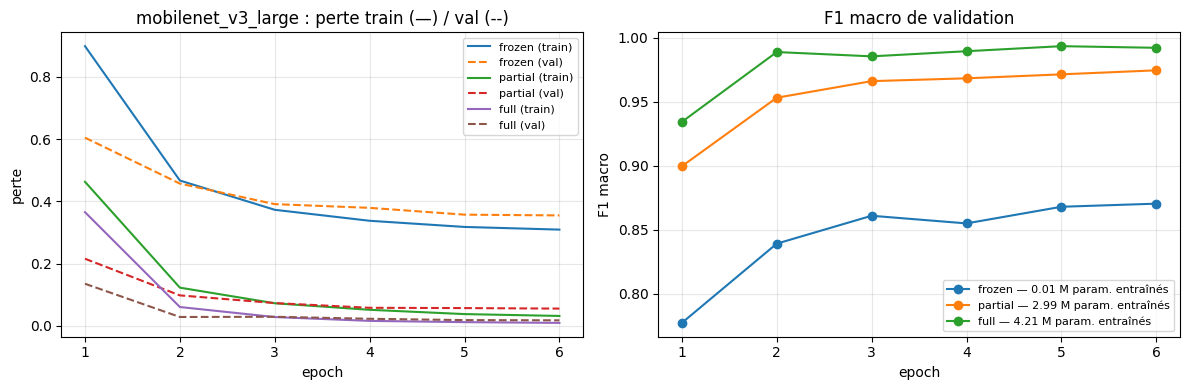

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (bb, strat), r in runs.items():
    h = r["hist"]
    axes[0].plot(h["epoch"], h["train_loss"], "-", label=f"{strat} (train)")
    axes[0].plot(h["epoch"], h["val_loss"], "--", label=f"{strat} (val)")
    axes[1].plot(h["epoch"], h["val_f1"], "o-", label=f"{strat} — {r['hp']['trainable_params'] / 1e6:.2f} M param. entraînés")
axes[0].set(xlabel="epoch", ylabel="perte", title=f"{P2['strategy_study_backbone']} : perte train (—) / val (--)")
axes[1].set(xlabel="epoch", ylabel="F1 macro", title="F1 macro de validation")
for a in axes:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "strategies.png", dpi=150)

best_strategy = max(P2["strategies"], key=lambda s: runs[(P2["strategy_study_backbone"], s)]["hist"]["val_f1"].max())
print("F1 val max :", {s: round(float(runs[(P2['strategy_study_backbone'], s)]["hist"]["val_f1"].max()), 4) for s in P2["strategies"]})
print("Stratégie retenue (validation) :", best_strategy)

# 3. Autres backbones avec la stratégie retenue

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 57.5MB/s]


Reprise depuis l'epoch 6 (temps déjà écoulé : 4.6 min)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


Reprise depuis l'epoch 6 (temps déjà écoulé : 6.6 min)


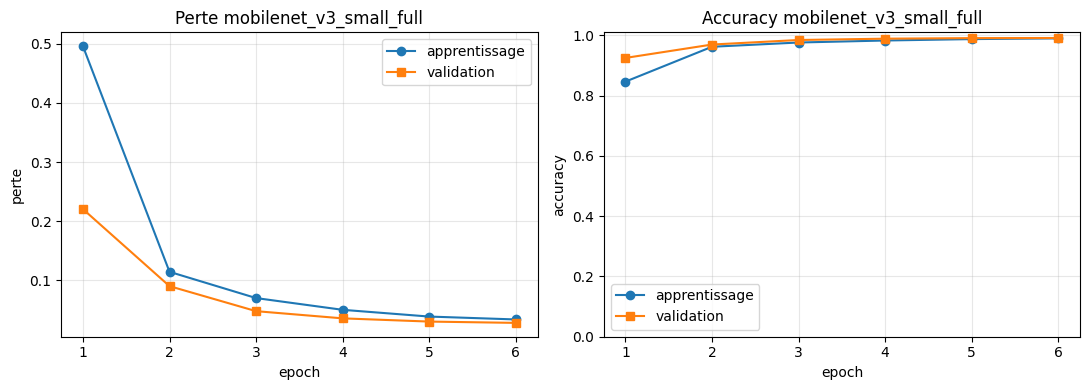

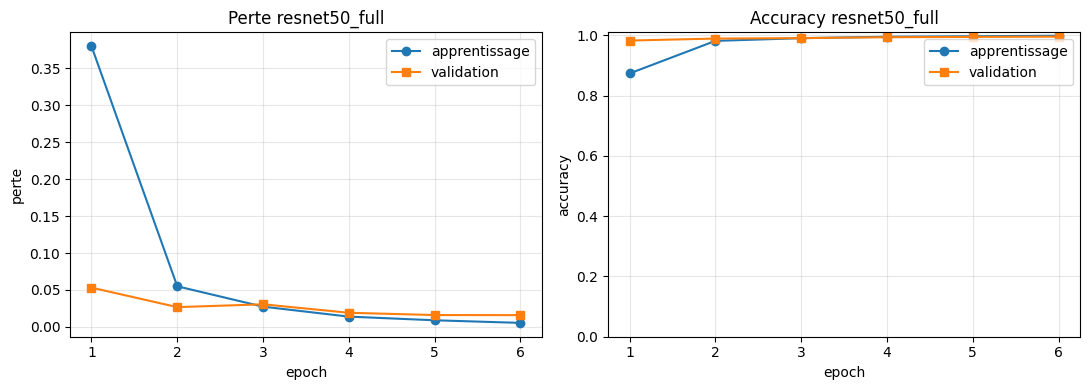

In [7]:
for bb in P2["backbones"]:
    if (bb, best_strategy) not in runs:
        runs[(bb, best_strategy)] = run_transfer(bb, best_strategy)

## 4. Évaluation sur le test et mesure des coûts

**Latence** (une image, batch = 1, cas d'usage réel) :
- *warm-up* de 20 passes exclues (allocations, initialisation cuDNN) puis moyenne sur 100 passes ;
- GPU : `torch.cuda.synchronize()` avant chaque lecture d'horloge (les noyaux CUDA sont asynchrones) ;
- CPU : **1 thread**, pour approcher un cœur de smartphone d'entrée de gamme et comparer les modèles à ressources égales. La machine utilisée est affichée par `machine_info()` (à citer dans le rapport). Les valeurs absolues d'un CPU de serveur ne sont pas celles d'un téléphone ARM : seul le **classement relatif** est transposable.

In [8]:
rows = []
lat_kw = dict(runs=P2["latency_runs"], warmup=P2["latency_warmup"])

def costs(model, img_size):
    c = {"latency_cpu_ms": measure_latency(model, img_size, "cpu", cpu_threads=P2["cpu_threads"], **lat_kw)["mean_ms"]}
    c["latency_gpu_ms"] = measure_latency(model, img_size, "cuda", **lat_kw)["mean_ms"] if torch.cuda.is_available() else None
    return c

for (bb, strat), r in runs.items():
    name = f"P2_{bb}_{strat}"
    m = load_best(r["model"], r["exp"])
    tm = final_test_evaluation(m, test_loader, CLASSES, r["exp"], name, guard, force=FORCE_TEST_RERUN)
    c = costs(m, SIZE)
    record_experiment(paths["results"], name, "2", m, r["exp"], SIZE, tm, r["hp"], **c)
    rows.append({"modèle": f"{bb} ({strat})", "famille": "transfer", "params_M": count_params(m) / 1e6,
                 "taille_Mo": model_size_mb(m), "val_f1": r["hist"]["val_f1"].max(), "test_acc": tm["accuracy"],
                 "test_f1": tm["f1_macro"], **c})

# Modèles du notebook 01 (déjà évalués sur le test là-bas : on relit leurs métriques, sans ré-évaluer)
P1 = cfg["part1"]
for name, m in [("CNN-Plain", CNNPlain(len(CLASSES), P1["channels"], dropout=P1["dropout"])),
                ("CNN-Res", CNNRes(len(CLASSES), P1["res_channels"], dropout=P1["dropout"]))]:
    exp = paths["results"] / "01_cnn_scratch" / name.lower()
    m = load_best(m, exp)
    tm = load_json(exp / "test_metrics.json")
    c = costs(m, cfg["resolution"]["scratch"])
    record_experiment(paths["results"], f"P1_{name}", "1", m, exp, cfg["resolution"]["scratch"], tm,
                      load_json(exp / "hparams.json"), **c)
    rows.append({"modèle": name, "famille": "from scratch", "params_M": count_params(m) / 1e6,
                 "taille_Mo": model_size_mb(m), "val_f1": pd.read_csv(exp / "history.csv")["val_f1"].max(),
                 "test_acc": tm["accuracy"], "test_f1": tm["f1_macro"], **c})

table = pd.DataFrame(rows).round(4)
table.to_csv(OUT / "comparison_costs.csv", index=False)
save_json(machine_info(), OUT / "latency_machine.json")
table

[P2_mobilenet_v3_large_frozen] déjà évalué sur le test : résultat relu depuis test_metrics.json
[P2_mobilenet_v3_large_partial] déjà évalué sur le test : résultat relu depuis test_metrics.json
[P2_mobilenet_v3_large_full] déjà évalué sur le test : résultat relu depuis test_metrics.json
[P2_mobilenet_v3_small_full] déjà évalué sur le test : résultat relu depuis test_metrics.json
[P2_resnet50_full] déjà évalué sur le test : résultat relu depuis test_metrics.json


,modèle,famille,params_M,taille_Mo,val_f1,test_acc,test_f1,latency_cpu_ms,latency_gpu_ms
0,mobilenet_v3_large (frozen),transfer,4.2148,17.1161,0.8703,0.9021,0.8832,21.2855,6.1955
1,mobilenet_v3_large (partial),transfer,4.2148,17.1161,0.9747,0.9809,0.9774,21.4048,6.0429
2,mobilenet_v3_large (full),transfer,4.2148,17.1161,0.9936,0.9960,0.9957,21.0809,6.8225
3,mobilenet_v3_small (full),transfer,1.5281,6.2866,0.9885,0.9905,0.9890,10.1237,5.4093
4,resnet50 (full),transfer,23.5285,94.4774,0.9947,0.9982,0.9978,123.6329,7.1818
5,CNN-Plain,from scratch,0.3544,1.4349,0.8437,0.8844,0.8481,9.8450,0.9317
6,CNN-Res,from scratch,0.2995,1.2224,0.7640,0.8096,0.7555,25.2675,1.9978


## 5. Front de Pareto

Un modèle est **Pareto-optimal** si aucun autre n'est à la fois plus rapide (ou plus léger) **et** plus précis. Les modèles hors du front sont « dominés » : il n'y a aucune raison de les déployer.

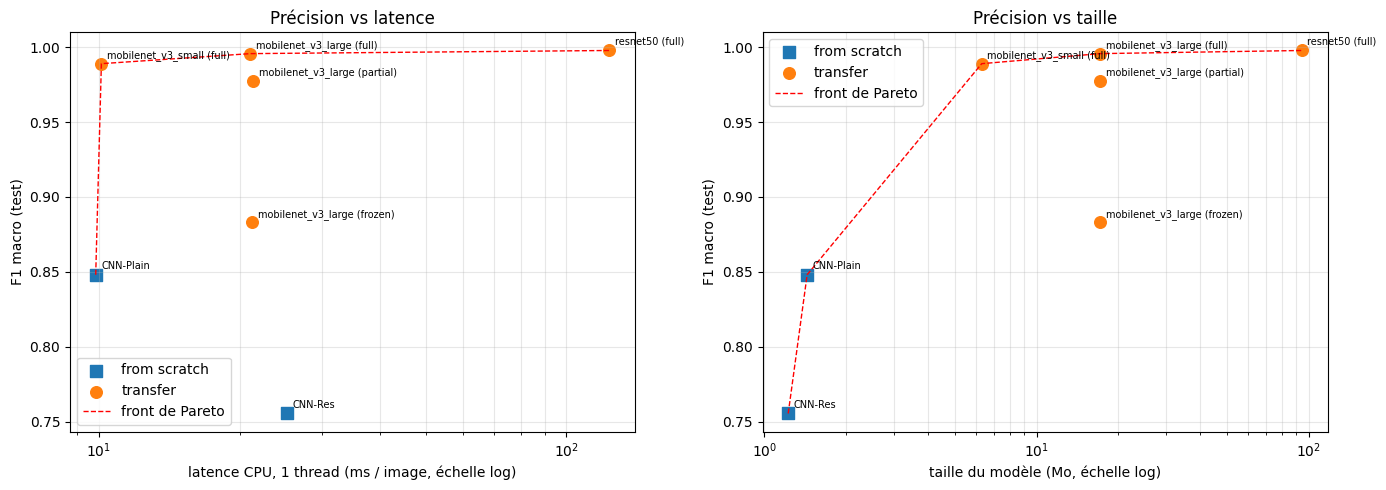

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, xl in [(axes[0], "latency_cpu_ms", "latence CPU, 1 thread (ms / image, échelle log)"),
                  (axes[1], "taille_Mo", "taille du modèle (Mo, échelle log)")]:
    front = pareto_front(table, x, "test_f1")
    for fam, mk in [("from scratch", "s"), ("transfer", "o")]:
        sub = table[table["famille"] == fam]
        ax.scatter(sub[x], sub["test_f1"], marker=mk, s=70, label=fam)
    f = table.loc[front].sort_values(x)
    ax.plot(f[x], f["test_f1"], "r--", lw=1, label="front de Pareto")
    for _, r in table.iterrows():
        ax.annotate(r["modèle"], (r[x], r["test_f1"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set(xscale="log", xlabel=xl, ylabel="F1 macro (test)")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
axes[0].set_title("Précision vs latence")
axes[1].set_title("Précision vs taille")
fig.tight_layout()
fig.savefig(OUT / "pareto.png", dpi=150)

 6. Meilleur classifieur (pour les notebooks 04 et 06)

Choisi sur la **validation** (F1 macro), jamais sur le test. Les chemins enregistrés sont relatifs à `results/`.

In [10]:
best_key = max(runs, key=lambda k: runs[k]["hist"]["val_f1"].max())
best = {"backbone": best_key[0], "strategy": best_key[1], "exp_dir": str(runs[best_key]["exp"].relative_to(paths["results"])),
        "val_f1": float(runs[best_key]["hist"]["val_f1"].max()), "img_size": SIZE}
save_json(best, OUT / "best_model.json")
best

{'backbone': 'resnet50',
 'strategy': 'full',
 'exp_dir': '02_transfer/resnet50_full',
 'val_f1': 0.9946736846211388,
 'img_size': 224}

 7. Recommandation pour un smartphone d'entrée de gamme (à rédiger avec VOS chiffres)

Grille de raisonnement :
- **Contraintes** : mémoire (taille < ~20 Mo souhaitable pour une app hors-ligne), latence (< ~200 ms ressentie comme instantanée), batterie (moins de calcul = moins d'énergie).
- Parmi les modèles **sur le front de Pareto**, lequel atteint une précision suffisante ? Quel gain de F1 apporte ResNet-50 et à quel coût (×latence, ×taille) ?
- Le plus souvent, **MobileNetV3-Large en fine-tuning complet** est le meilleur compromis ; MobileNetV3-Small si la latence est critique. Justifier par les mesures, pas par l'intuition.

 8. *Bonus* — export ONNX + quantification dynamique INT8

ONNX Runtime est disponible sur Android/iOS : c'est un chemin de déploiement réaliste. La **quantification dynamique** stocke les poids en INT8 (×4 moins de mémoire) et quantifie les activations à la volée. Deux variantes : toutes les couches, ou seulement les couches denses. On mesure le gain de taille et de latence, et la perte de précision **sur la validation** (le test ne sert pas à valider une transformation du modèle).

In [11]:
DEPLOY = ("mobilenet_v3_large", best_strategy)   # à adapter selon votre recommandation
r = runs[DEPLOY]
m = load_best(TransferModel(DEPLOY[0], len(CLASSES), pretrained=False), r["exp"]).cpu()
onnx_fp32 = export_onnx(m, SIZE, r["exp"] / "model_fp32.onnx")
onnx_int8_all = quantize_onnx_dynamic(onnx_fp32, r["exp"] / "model_int8_all.onnx")
onnx_int8_dense = quantize_onnx_dynamic(onnx_fp32, r["exp"] / "model_int8_dense.onnx", op_types=["MatMul", "Gemm"])

y_val = data["val"][0]["label"].to_numpy()
q_rows = []
for label, f in [("ONNX FP32", onnx_fp32), ("INT8 dynamique — toutes couches", onnx_int8_all),
                 ("INT8 dynamique — couches denses", onnx_int8_dense)]:
    lat = onnx_latency(f, SIZE, P2["latency_runs"], P2["latency_warmup"], threads=P2["cpu_threads"])
    pred = onnx_predict(f, val_loader)
    q_rows.append({"format": label, "taille_Mo": lat["size_mb"], "latence_cpu_ms": lat["mean_ms"],
                   "val_acc": accuracy_score(y_val, pred), "val_f1": f1_score(y_val, pred, average="macro")})
quant = pd.DataFrame(q_rows).round(4)
quant["gain_taille"] = (quant["taille_Mo"].iloc[0] / quant["taille_Mo"]).round(2)
quant["gain_latence"] = (quant["latence_cpu_ms"].iloc[0] / quant["latence_cpu_ms"]).round(2)
quant.to_csv(OUT / "onnx_quantization.csv", index=False)
quant

,format,taille_Mo,latence_cpu_ms,val_acc,val_f1,gain_taille,gain_latence
0,ONNX FP32,16.8539,8.3914,0.9945,0.9936,1.00,1.00
1,INT8 dynamique — toutes couches,4.4523,95.3905,0.4875,0.2631,3.79,0.09
2,INT8 dynamique — couches denses,13.1455,7.7281,0.9941,0.9932,1.28,1.09


**À commenter** (avec vos chiffres) :
- **taille** : divisée par ~4 quand les convolutions sont quantifiées (poids INT8), gain partiel si seules les couches denses le sont (part des paramètres denses : voir `torchinfo`) ;
- **latence** : la quantification **dynamique** des convolutions (ConvInteger) est souvent **plus lente** sur CPU x86 que les convolutions float très optimisées, car les activations sont quantifiées/déquantifiées à chaque couche. Sur un smartphone ARM, le résultat peut différer : il faut mesurer sur la cible ;
- **précision** : vérifier la perte sur la validation ;
- perspective : quantification **statique** (format QDQ, calibration sur quelques centaines d'images d'apprentissage) ou *quantization-aware training*, et export TFLite / ONNX Runtime Mobile.